In [171]:
# Importing the necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Importing Dataset and performing EDA

In [ ]:
# Importing the dataset
df = pd.read_csv('freMTPL2freq.csv')

In [173]:
df.head()

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


In [174]:
print(f'Rows x Columns : {df.shape}')

Rows x Columns : (678013, 12)


In [175]:
# Checking the datatypes of all the columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  float64
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   VehPower    678013 non-null  int64  
 4   VehAge      678013 non-null  int64  
 5   DrivAge     678013 non-null  int64  
 6   BonusMalus  678013 non-null  int64  
 7   VehBrand    678013 non-null  object 
 8   VehGas      678013 non-null  object 
 9   Area        678013 non-null  object 
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  object 
dtypes: float64(2), int64(6), object(4)
memory usage: 62.1+ MB


In [176]:
# Checking for null values
df.isnull().sum()
# No null values

IDpol         0
ClaimNb       0
Exposure      0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Area          0
Density       0
Region        0
dtype: int64

In [177]:
# Checking for duplicates
print(f"Number of duplicates in the dataset : {df.duplicated().sum()}")

Number of duplicates in the dataset : 0


In [178]:
# Checking mean, standard deviation, quantile etc of the numeric data only
df.describe().round(2)

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,678013.00,678013.00,678013.00,678013.00,678013.00,678013.00,678013.00,678013.00
mean,2621856.92,0.05,0.53,6.45,7.04,45.50,59.76,1792.42
std,1641782.75,0.24,0.36,2.05,5.67,14.14,15.64,3958.65
min,1.00,0.00,0.00,4.00,0.00,18.00,50.00,1.00
25%,1157951.00,0.00,0.18,5.00,2.00,34.00,50.00,92.00
50%,2272152.00,0.00,0.49,6.00,6.00,44.00,50.00,393.00
75%,4046274.00,0.00,0.99,7.00,11.00,55.00,64.00,1658.00
max,6114330.00,16.00,2.01,15.00,100.00,100.00,230.00,27000.00


In [179]:
# Checking the skewness of numeric columns only
# closer to 0 means symmetric data and higher values means stronger positive skewness
# Sorting them in descending order of skewness
df.skew(numeric_only=True).sort_values(ascending=False)

ClaimNb       5.599613
Density       4.651421
BonusMalus    1.728934
VehPower      1.171344
VehAge        1.147989
DrivAge       0.435759
IDpol         0.237890
Exposure      0.085318
dtype: float64

Checking the counts of categorical columns and its plot

Unique Values in VehBrand:
VehBrand
B12    166024
B1     162736
B2     159861
B3      53395
B5      34753
B6      28548
B4      25179
B10     17707
B11     13585
B13     12178
B14      4047
Name: count, dtype: int64


<Axes: xlabel='VehBrand', ylabel='count'>

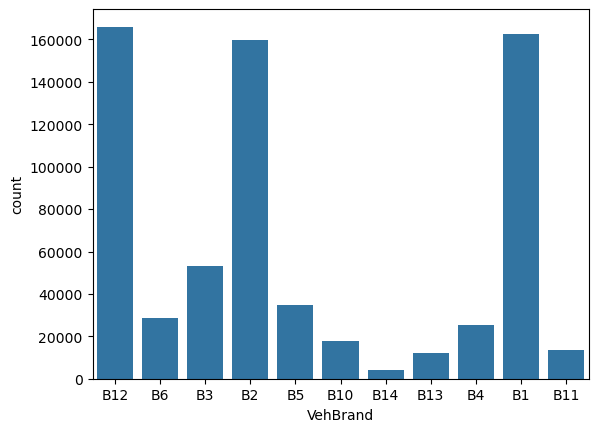

In [180]:
# Checking the unique values and its occurences of Vehicle Brand
# Categories are unknown
print("Unique Values in VehBrand:")
print(df['VehBrand'].value_counts())
sns.countplot(x = df['VehBrand'])

# Category is unevenly distributed
# B12, B2 and B1 heavily dominate the category

Unique Values in VehGas:
VehGas
Regular    345877
Diesel     332136
Name: count, dtype: int64


<Axes: xlabel='VehGas', ylabel='count'>

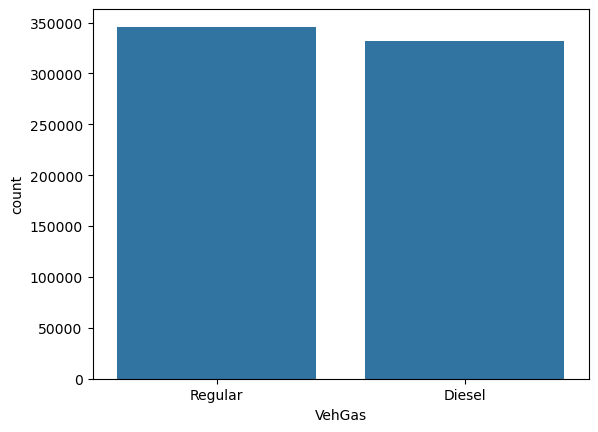

In [181]:
# Checking the unique values and its occurences of Vehicle's Fuel Type
# Regular - Petrol and Diesel
print("Unique Values in VehGas:")
print(df['VehGas'].value_counts())
sns.countplot(x = df['VehGas'])

# Both the type have even distribution in the Category

Unique values in Area:
Area
A    103957
B     75459
C    191880
D    151596
E    137167
F     17954
Name: count, dtype: int64


<Axes: xlabel='Area', ylabel='count'>

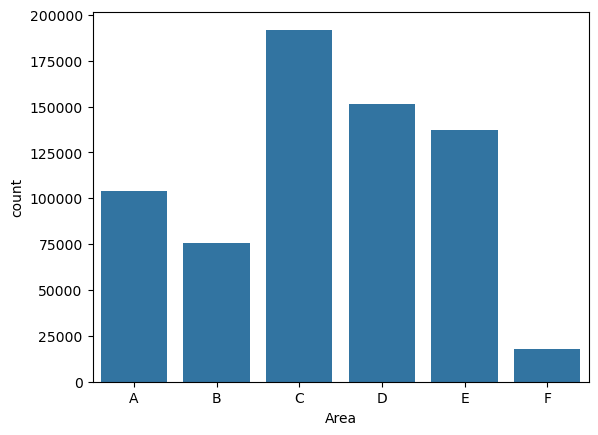

In [182]:
# Checking the unique values and its occurences of Type of Area of the car driver
# Categories go from A - Rural area to F - Urban Area
print('Unique values in Area:')
print(df['Area'].value_counts().sort_index())
sns.countplot(x = df['Area'].sort_values())

# Rural area has less representation
# while areas of semi-rural and semi-urban have good amount of representation in the data

Unique Values of Region:
Region
Centre                         160601
Rhone-Alpes                     84752
Provence-Alpes-Cotes-D'Azur     79315
Ile-de-France                   69791
Bretagne                        42122
Nord-Pas-de-Calais              40275
Pays-de-la-Loire                38751
Languedoc-Roussillon            35805
Aquitaine                       31329
Poitou-Charentes                19046
Midi-Pyrenees                   17141
Basse-Normandie                 10893
Bourgogne                       10492
Haute-Normandie                  8784
Picardie                         7994
Auvergne                         5287
Limousin                         4567
Corse                            4516
Champagne-Ardenne                3026
Alsace                           2200
Franche-Comte                    1326
Name: count, dtype: int64


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
 [Text(0, 0, 'Rhone-Alpes'),
  Text(1, 0, 'Picardie'),
  Text(2, 0, 'Aquitaine'),
  Text(3, 0, 'Nord-Pas-de-Calais'),
  Text(4, 0, 'Languedoc-Roussillon'),
  Text(5, 0, 'Pays-de-la-Loire'),
  Text(6, 0, "Provence-Alpes-Cotes-D'Azur"),
  Text(7, 0, 'Ile-de-France'),
  Text(8, 0, 'Centre'),
  Text(9, 0, 'Corse'),
  Text(10, 0, 'Auvergne'),
  Text(11, 0, 'Poitou-Charentes'),
  Text(12, 0, 'Bourgogne'),
  Text(13, 0, 'Bretagne'),
  Text(14, 0, 'Midi-Pyrenees'),
  Text(15, 0, 'Alsace'),
  Text(16, 0, 'Basse-Normandie'),
  Text(17, 0, 'Champagne-Ardenne'),
  Text(18, 0, 'Franche-Comte'),
  Text(19, 0, 'Limousin'),
  Text(20, 0, 'Haute-Normandie')])

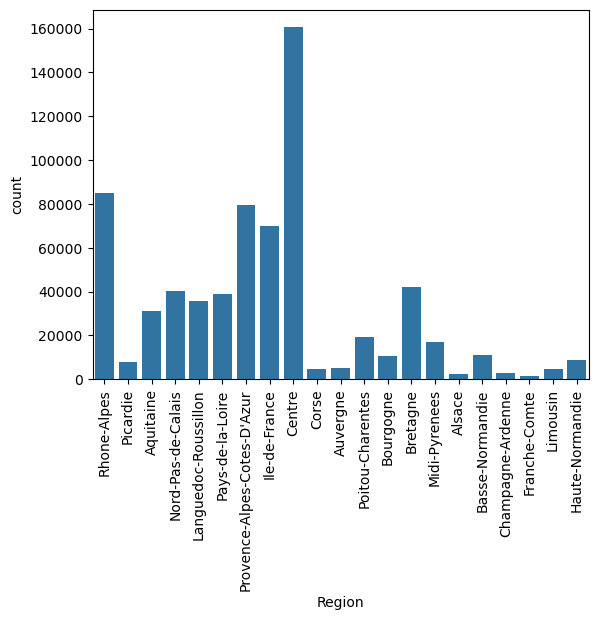

In [183]:
# Checking the unique values and its occurences of Type of Area of the car driver
print('Unique Values of Region:')
print(df['Region'].value_counts())
sns.countplot(x = df['Region'])
plt.xticks(rotation=90)

# very uneven distribution
# regions - centre has substantially more observation in the category

Checking the distribution and value counts of Numerical columns

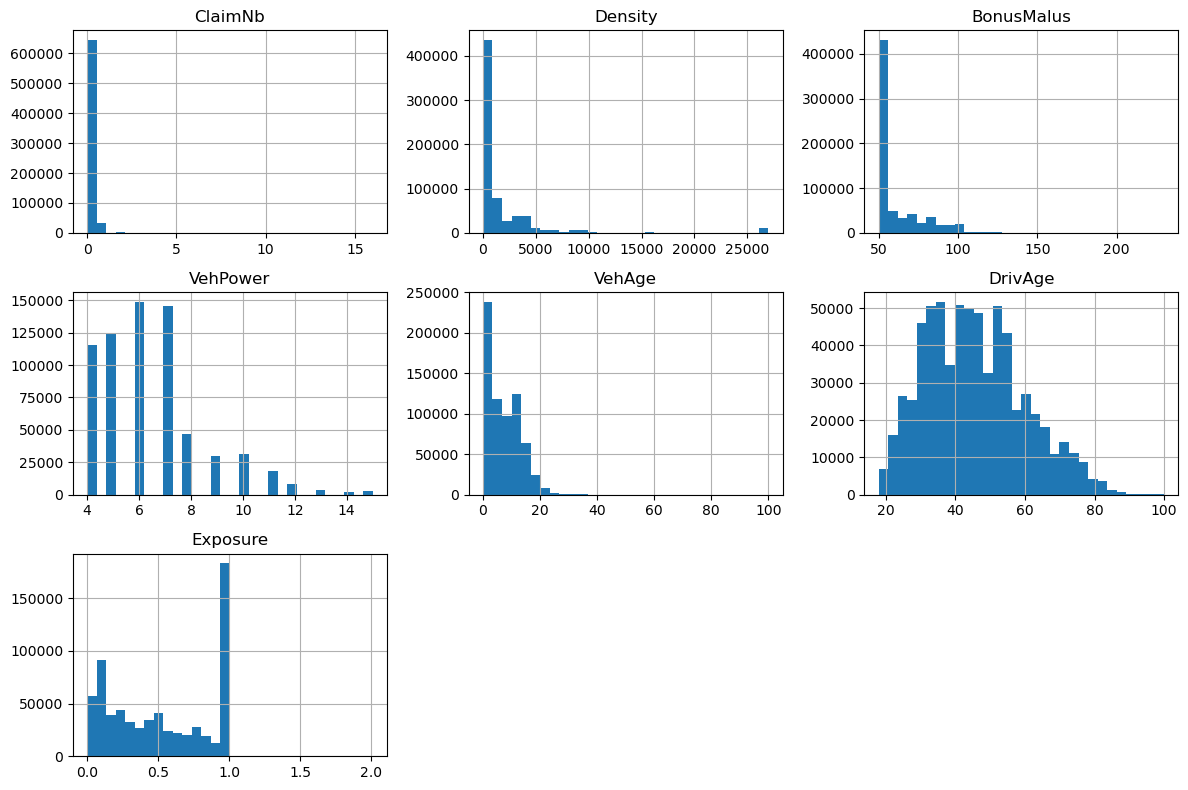

In [184]:
cols = ["ClaimNb","Density","BonusMalus","VehPower","VehAge","DrivAge","Exposure"]

df[cols].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

In [185]:
# high positive skew of Claim Number, Density and BonusMalus 
# Claim number has discrete values
# so Poisson or Negative Binomial distribution could be fit for ClaimNb
# this is our target variable

# Vehicle Power (Discrete), Vehicle Age (Continuous) and Driver Age (Continuous)
# have moderate positive skewness 

# Exposure is approximately symetric
# A large number of policyholders have policy exposure of 1 year, very few policyholders have exposure of more than 1 year

In [186]:
# Further Analysis of ClaimNB (Target Column)

print(f"Total claims: {df['ClaimNb'].sum()}")
print(f"Total Policies: {len(df)}")
print(f"Policies with atleast one claim: {(df['ClaimNb'] > 0).sum()}")
print(f"Percentage of Policies with atleast 1 claim: {round((df['ClaimNb'] > 0).mean()*100,3)} %")
print(df['ClaimNb'].value_counts().sort_index())

# Most policies have no claims, approximately 95% of the policies had 0 claims
# during their exposure period

# Very strong positive skewness and a long tail (higher values have very less observation)
# as observed from skewness value and histogram plotted earlier

# Claim Numbers are discrete and non-negative
# assuming Poisson distribution for it seems a sensible starting point

Total claims: 36102
Total Policies: 678013
Policies with atleast one claim: 34060
Percentage of Policies with atleast 1 claim: 5.024 %
ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64


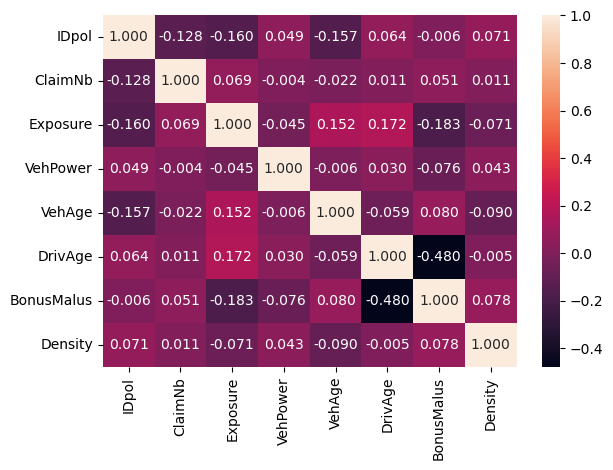

In [187]:
# Correlation Matrix (Numeric columns only)
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt=".3f")
plt.tight_layout()

# DriverAge and BonusMalus has a moderate negative relationship
# older drivers tends to have lower bonus valus

# most other variables shows weak correlations

# Adjusted Claim Frequency
Because we have different exposure times for different individuals, raw claim counts are not comparable

Claim frequency is calculated as Claims/Exposure

This would help identify how claim frequency varies across the different features such as Area, Fuel Type etc

In [188]:
# Adjusted Claim Frequancy by Area
frequancy_by_area = (df.groupby("Area").agg(
    Claims = ("ClaimNb","sum"),
    Exposure = ("Exposure","sum")
))
frequancy_by_area["Frequency"] = (frequancy_by_area["Claims"]/frequancy_by_area["Exposure"])
frequancy_by_area

,Claims,Exposure,Frequency
Area,,,
A,5063,61969.377712,0.081702
B,3800,43012.323931,0.088347
C,9875,104449.003784,0.094544
D,8428,77120.191692,0.109284
E,7805,63819.314270,0.122298
F,1131,8129.234074,0.139127


In [189]:
# Adjusted Claim Frequancy by Gas
frequancy_by_gas = (df.groupby("VehGas").agg(
    Claims = ("ClaimNb","sum"),
    Exposure = ("Exposure","sum")
))
frequancy_by_gas["Frequency"] = (frequancy_by_gas["Claims"]/frequancy_by_gas["Exposure"])
frequancy_by_gas

,Claims,Exposure,Frequency
VehGas,,,
Diesel,16648,170660.893126,0.097550
Regular,19454,187838.552336,0.103568


# Poisson GLM

Dataset Preprocessing

In [190]:
# Dividing data into predictors and target data
df = df.drop("IDpol",axis=1)  # dropping column "IDpol" as it would not be used further in the project
X = df.drop(["ClaimNb","Exposure"],axis=1)  # dropping target column, "Exposure" to be used as an offset in the GLM
exposure = df["Exposure"]
y = df["ClaimNb"]  # target column

print(f"Predictors shape: {X.shape}")
print(f"Target shape: {y.shape}")

Predictors shape: (678013, 9)
Target shape: (678013,)


In [191]:
# Dividing data into training and testing data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test, exp_train, exp_test = train_test_split( X, y, exposure,
                                                                         test_size=0.2, random_state=42)

In [192]:
# Selecting categorical columns from the data
categorical_columns = X_train.select_dtypes(include=["object"]).columns.tolist()
print(f"Categorical columns: {categorical_columns}")

Categorical columns: ['VehBrand', 'VehGas', 'Area', 'Region']


In [193]:
# Encoding categorical columns
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers = [("cat",OneHotEncoder(drop="first",handle_unknown="ignore"),categorical_columns)],
    remainder="passthrough")

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.fit_transform(X_test)

# To check is the number of features are same in predictors
print(f"Same number of columns: {X_train_encoded.shape[1] == X_test_encoded.shape[1]}")

Same number of columns: True


Fitting the Poisson GLM

In [194]:
# Importing necessary library
import statsmodels.api as sm

In [195]:
# GLM includes an intercept, which is the output when all predictors are 0
# Adding intercept parameter which is required by GLM in predictor variables
X_train_glm = sm.add_constant(X_train_encoded.toarray(), has_constant="add")
X_test_glm = sm.add_constant(X_test_encoded.toarray(), has_constant="add")

In [196]:
# Creating the Poisson GLM
poisson_model = sm.GLM(y_train,X_train_glm,
                     family=sm.families.Poisson(),
                     offset=np.log(exp_train))

# Fitting the GLM model
poisson_results = poisson_model.fit()

# Summary of the Poisson GLM
print(poisson_results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:                            GLM   Df Residuals:                   542368
Model Family:                 Poisson   Df Model:                           41
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1455e+05
Date:                Sat, 10 Oct 2026   Deviance:                   1.7370e+05
Time:                        18:10:07   Pearson chi2:                 1.42e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01070
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -4.0391      0.109    -37.070      0.0

In [197]:
# Interpretation of the output of GLM

# log likelihood = -114556
# log likelihood measures how well the model is fitted to observed values
# it could be interpreted when comparing to another fitted glm, higher value is preferable

# deviance = 173700
# measures tthe discrepancy between fitted model and a saturated model
# lower deviance indicates a better model when compared to another model

# pearson dispersion ratio = pearson chi-square/df residual = 742000/542368 = 1.368 
# since ratio > 1, it shows overdispersion
# the actual variance in claim number might exceed the variance calculated by the Poisson GLM



In [198]:
# getting the feature names out to write the equation
feature_names = preprocessor.get_feature_names_out()
print(feature_names)

['cat__VehBrand_B10' 'cat__VehBrand_B11' 'cat__VehBrand_B12'
 'cat__VehBrand_B13' 'cat__VehBrand_B14' 'cat__VehBrand_B2'
 'cat__VehBrand_B3' 'cat__VehBrand_B4' 'cat__VehBrand_B5'
 'cat__VehBrand_B6' 'cat__VehGas_Regular' 'cat__Area_B' 'cat__Area_C'
 'cat__Area_D' 'cat__Area_E' 'cat__Area_F' 'cat__Region_Aquitaine'
 'cat__Region_Auvergne' 'cat__Region_Basse-Normandie'
 'cat__Region_Bourgogne' 'cat__Region_Bretagne' 'cat__Region_Centre'
 'cat__Region_Champagne-Ardenne' 'cat__Region_Corse'
 'cat__Region_Franche-Comte' 'cat__Region_Haute-Normandie'
 'cat__Region_Ile-de-France' 'cat__Region_Languedoc-Roussillon'
 'cat__Region_Limousin' 'cat__Region_Midi-Pyrenees'
 'cat__Region_Nord-Pas-de-Calais' 'cat__Region_Pays-de-la-Loire'
 'cat__Region_Picardie' 'cat__Region_Poitou-Charentes'
 "cat__Region_Provence-Alpes-Cotes-D'Azur" 'cat__Region_Rhone-Alpes'
 'remainder__VehPower' 'remainder__VehAge' 'remainder__DrivAge'
 'remainder__BonusMalus' 'remainder__Density']


In [199]:
# the equation for the GLM:
# Note: the equation is truncated because i just wanted to display the logic behind
#       how the equation is formed from the coefficients and the features
# log is the default link function for Poisson GLM
# log(mu_i) = log(e_i) + (-4.0391) + (-0.0403 * cat__VehBrand_B10) + (0.0276 * cat__VehBrand_B11) + (0.1646 * cat__VehBrand_B12) + (0.0054 * cat__VehBrand_B13) + ... + (0.0225 * remainder__BonusMalus) + (-0.0000 * remainder__Density)

In [200]:
# Generating Predictions for the GLM
y_pred_glm = poisson_results.predict(X_test_glm,offset=np.log(exp_test))
print(y_pred_glm[:5])

# Left side: IDpol i.e. policyID
# Right side: Predicted expected number of claims for that policyID
# the predictions are in decimals because the expected claim number are over the policy's exposure period
# these are not the predicted claim numbers

261354    0.064653
448143    0.019107
188618    0.058142
12952     0.054461
425028    0.031351
Name: Exposure, dtype: float64


GLM Evaluation Metrics

In [201]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,mean_poisson_deviance

mae_glm = mean_absolute_error(y_test,y_pred_glm)
rmse_glm = np.sqrt(mean_squared_error(y_test,y_pred_glm))
poisson_deviance_glm = mean_poisson_deviance(y_test,y_pred_glm)

print(f"MAE: {mae_glm:.5f}")
print(f"RMSE: {rmse_glm:.5f}")
print(f"Mean Poisson Deviance: {poisson_deviance_glm:.5f}")

MAE: 0.09889
RMSE: 0.23733
Mean Poisson Deviance: 0.32159


In [202]:
# MAE = 0.09889
# Mean of the absolute difference between actual and predicted values

# RMSE = 0.23733
# Prediction errors, larger errors penalised heavily

# Mean Poisson Deviance = 0.32159
# Difference between observed values and predicted Poisson values

# All these metrics are comparative to other model's metrics
# we will be comparing these metrics to models fitted using ML algorithms
# Lower the better for all these metrics

# ML Algorithm: Decision Tree

For an appropriate comparison between the GLM, i would be trying to account for Exposure in the Decision Tree seperately as done in the GLM

In [203]:
# Initialising the Decision Tree
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(criterion="poisson",
                                   max_depth=5,
                                   min_samples_leaf=100,
                                   random_state=42)

In [204]:
# Training and Predictions from the Decision Tree
# trying to incorporate the exposure offset in decision tree
tree_model.fit(X_train_encoded,y_train,sample_weight=exp_train)
y_pred_tree = tree_model.predict(X_test_encoded)

In [205]:
# Decision Tree Evaluation Metrics
mae_tree = mean_absolute_error(y_test,y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test,y_pred_tree))
poisson_deviance_tree = mean_poisson_deviance(y_test,y_pred_tree)

print(f"MAE: {mae_tree:.5f}")
print(f"RMSE: {rmse_tree:.5f}")
print(f"Mean Poisson Deviancce: {poisson_deviance_tree:.5f}")

MAE: 0.11214
RMSE: 0.23796
Mean Poisson Deviancce: 0.31564


In [206]:
model_comparison = pd.DataFrame({
    "Evaluation Metric": ["MAE","RMSE","Mean Poisson Deviance"],
    "Poisson GLM": [mae_glm,rmse_glm,poisson_deviance_glm],
    "Decision Tree": [mae_tree,rmse_tree,poisson_deviance_tree]
})
model_comparison.round(5)

,Evaluation Metric,Poisson GLM,Decision Tree
0,MAE,0.09889,0.11214
1,RMSE,0.23733,0.23796
2,Mean Poisson Deviance,0.32159,0.31564


In [207]:
# the MAE for Decision Tree is higher than for Poisson GLM
# This suggests that GLM's predictions are closer to actual claim number when considering absolute differences

# small difference between RMSE for Decision Tree and Poisson GLM
# the result suggests that the two models have very similar prediction performance

# for Mean Poisson Deviance, the Decision Tree performed slightly better

# we could try to improve the performance of the Decision Tree or try a different algorithm altogether
# I would be proceeding with fitting a Random Forest algorithm

# ML Algorithm: Random Forest Regressor

Trying to account for Exposure as done in Decision Tree model and Poisson GLM

In [208]:
# Initialising the Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=50,
                                 max_depth=10,
                                 min_samples_leaf=100,
                                 random_state=42,
                                 n_jobs=-1)

In [210]:
# Training and predicting using Random Forest
rf_model.fit(X_train_encoded,y_train,sample_weight=exp_train)
y_pred_rf = rf_model.predict(X_test_encoded)

In [212]:
# Random Forest Evaluation Metrics
mae_rf = mean_absolute_error(y_test,y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test,y_pred_rf))
poisson_deviance_rf = mean_poisson_deviance(y_test,y_pred_rf)

print(f"MAE: {mae_rf:.5f}")
print(f"RMSE: {rmse_rf:.5f}")
print(f"Mean Poisson Deviancce: {poisson_deviance_rf:.5f}")

MAE: 0.11042
RMSE: 0.23654
Mean Poisson Deviancce: 0.30887


In [213]:
model_comparison = pd.DataFrame({
    "Evaluation Metric": ["MAE","RMSE","Mean Poisson Deviance"],
    "Poisson GLM": [mae_glm,rmse_glm,poisson_deviance_glm],
    "Decision Tree": [mae_tree,rmse_tree,poisson_deviance_tree],
    "Random Forest": [mae_rf,rmse_rf,poisson_deviance_rf]
})
model_comparison.round(5)

,Evaluation Metric,Poisson GLM,Decision Tree,Random Forest
0,MAE,0.09889,0.11214,0.11042
1,RMSE,0.23733,0.23796,0.23654
2,Mean Poisson Deviance,0.32159,0.31564,0.30887


In [214]:
# Comparison of all Evaluation metrics
# for all metrics, lower the value, better the model

# Mean Absolute Error: Poisson GLM performs best here
# this suggests GLM produces smaller average absolute errors while predicting

# Root Mean Squared Error: Random Forest performs best here
# although the difference is very small between all, Random forest has slight advantage

# Mean Poisson Deviance: Random Forest performs best here
# Value for Random Forest is 3.95% lower than Poisson GLM

Final Conclusions and Interpretations

In [ ]:
# There isn't always a single model performing the best across all metrics
# The Poisson GLM achieved the lowest MAE, Random Forest performed best in terms of RMSE and Mean Poisson Deviance.
# The Random Forest outperformed the single Decision Tree across all three evaluation metrics.

# Further improvements could be explored using trial and error, 
# such as using Negative Binomial GLM or
# tuning parameters of existing ML algorithms or trying new algorithms altogether such as Boosting

In [215]:
# Limitations and Drawbacks

# Exposure Treatment:
# The GLM accounts for exposure through a log-offset, whereas the Decision Tree
# and Random Forest use exposure as sample weights. This limits direct comparability.

# Class Imbalance:
# Most policies have zero claims, making it difficult for models to predict
# the relatively rare occurrence of claims accurately (approximately 5% non-zero claim number rows).

# Generalisation:
# The models were evaluated on a much cleaner and ready to be used sample from the same dataset.
# Their performance may differ on other portfolios or future insurance data.